# **CNN Facial Expression Recognizion**
## *Model Building*

In [1]:
#Importing necessary libs
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input, Dropout, BatchNormalization
from keras.callbacks import EarlyStopping
from keras.preprocessing import image
from tensorflow.keras.models import load_model

print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available: 1


In [2]:
#Connecting to drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#Extracting the files the model will train/test on to a new folder in the drive
import zipfile
zip_file = '/content/drive/MyDrive/content/archive.zip'

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
  zip_ref.extractall('/content/dataset')

In [4]:
#Training data generator with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

# Testing data generator — only normalization, no augmentation
test_datagen = ImageDataGenerator(rescale=1./255)

In [5]:
training_set = train_datagen.flow_from_directory(
    '/content/dataset/train',
    target_size=(48,48),
    color_mode='grayscale',
    batch_size=32,
    class_mode='categorical'
)

test_set= test_datagen.flow_from_directory(
    '/content/dataset/test',
    target_size=(48,48),
    color_mode='grayscale',
    batch_size=32,
    class_mode='categorical'
)

Found 28709 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.


In [6]:
#Checking the indices of each emotion
print(training_set.class_indices)

{'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


In [9]:
#Making the model
model = Sequential([
    #Input Layer
    Input(shape=(48,48,1)),
    #First Convolutional Layer
    Conv2D(32, 3, activation='relu'),MaxPooling2D(2),
    #Second Convolutional Layer
    Conv2D(32, 3, activation='relu'),MaxPooling2D(2),
    #Flatten
    Flatten(),
    #Fully Connected
    Dense(128, activation='relu'),
    Dense(7,activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420,199 (1.60 MB)

 Trainable params: 420,199 (1.60 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

stop= EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(training_set, validation_data= test_set, epochs=20, callbacks=[stop])

Epoch 1/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 40s 37ms/step - accuracy: 0.3307 - loss: 1.6846 - val_accuracy: 0.4053 - val_loss: 1.5391
Epoch 2/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 25s 27ms/step - accuracy: 0.4114 - loss: 1.5250 - val_accuracy: 0.4457 - val_loss: 1.4390
Epoch 3/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 25s 28ms/step - accuracy: 0.4383 - loss: 1.4533 - val_accuracy: 0.4820 - val_loss: 1.3535
Epoch 4/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 26s 29ms/step - accuracy: 0.4612 - loss: 1.4063 - val_accuracy: 0.4921 - val_loss: 1.3307
Epoch 5/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 26s 29ms/step - accuracy: 0.4772 - loss: 1.3675 - val_accuracy: 0.5028 - val_loss: 1.3037
Epoch 6/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - accuracy: 0.4882 - loss: 1.3347 - val_accuracy: 0.5095 - val_loss: 1.2763
Epoch 7/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 25s 28ms/step - accuracy: 0.4986 - loss: 1.3157 - val_accuracy: 0.5156 - val_loss: 1.2609
Epoch 8/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 25s 28ms/step - accuracy: 0.5039 - loss: 1.2964 - 

In [11]:
model.save('/content/drive/MyDrive/fer_cnn_model.keras')

In [7]:
model2 = load_model('/content/drive/MyDrive/fer_cnn_model_v2.keras')

In [21]:
#Making a better model
model2 = Sequential([
    Input(shape=(48,48,1)),
    Conv2D(32, 3, padding='same', activation='relu'), BatchNormalization(),
    Conv2D(32, 3, padding='same', activation='relu'), BatchNormalization(),
    MaxPooling2D(2), Dropout(0.25),
    Conv2D(64, 3, padding='same', activation='relu'), BatchNormalization(),
    Conv2D(64, 3, padding='same', activation='relu'), BatchNormalization(),
    MaxPooling2D(2), Dropout(0.25),
    Conv2D(128, 3, padding='same', activation='relu'), BatchNormalization(),
    Conv2D(128, 3, padding='same', activation='relu'), BatchNormalization(),
    MaxPooling2D(2), Dropout(0.25),
    Flatten(),
    Dense(128, activation='relu'), BatchNormalization(), Dropout(0.5),
    Dense(7, activation='softmax')
])

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 879,591 (3.36 MB)

 Trainable params: 878,439 (3.35 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [8]:
from keras.callbacks import ReduceLROnPlateau

model2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
               loss='categorical_crossentropy', metrics=['accuracy'])

reduce = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001)
stop2 = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

model2.fit(training_set, validation_data=test_set, epochs=30, callbacks=[stop2, reduce])

Epoch 1/30
898/898 ━━━━━━━━━━━━━━━━━━━━ 78s 59ms/step - accuracy: 0.6092 - loss: 1.0382 - val_accuracy: 0.6382 - val_loss: 0.9871 - learning_rate: 3.0000e-04
Epoch 2/30
898/898 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/step - accuracy: 0.6194 - loss: 1.0287 - val_accuracy: 0.6280 - val_loss: 0.9999 - learning_rate: 3.0000e-04
Epoch 3/30
898/898 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/step - accuracy: 0.6170 - loss: 1.0210 - val_accuracy: 0.6294 - val_loss: 0.9827 - learning_rate: 3.0000e-04
Epoch 4/30
898/898 ━━━━━━━━━━━━━━━━━━━━ 29s 32ms/step - accuracy: 0.6241 - loss: 1.0094 - val_accuracy: 0.6411 - val_loss: 0.9714 - learning_rate: 3.0000e-04
Epoch 5/30
898/898 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/step - accuracy: 0.6244 - loss: 1.0038 - val_accuracy: 0.6321 - val_loss: 0.9938 - learning_rate: 3.0000e-04
Epoch 6/30
898/898 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/step - accuracy: 0.6285 - loss: 0.9905 - val_accuracy: 0.6406 - val_loss: 0.9739 - learning_rate: 3.0000e-04
Epoch 7/30
898/898 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/ste

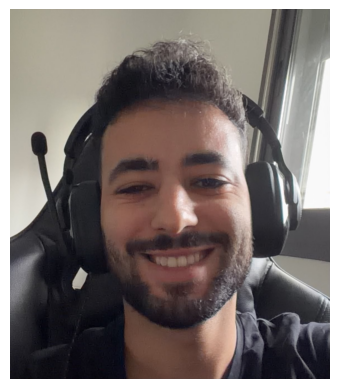

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
happy 76.35%
angry 3.1%
disgust 0.1%
fear 2.5%
happy 76.3%
neutral 13.9%
sad 3.5%
surprise 0.6%


In [23]:
#Testing the model on a selfie and checking the probablities of each class
img_path = '/content/drive/MyDrive/content/a227fd30-a56d-48d3-bba8-b84a56ba706d.jpg'
img = image.load_img(img_path, target_size=(48,48), color_mode='grayscale')
x = image.img_to_array(img) / 255
x = np.expand_dims(x, axis=0)

og_img = image.load_img(img_path)
plt.imshow(og_img)
plt.axis('off')
plt.show()

probs = model2.predict(x)
names = {v: k for k, v in training_set.class_indices.items()}
print(names[np.argmax(probs)], f"{np.max(probs):.2%}")

for i, p in enumerate(probs[0]):
    print(names[i], f"{p:.1%}")

In [9]:
model2.save('/content/drive/MyDrive/fer_cnn_model_v3.keras')

In [13]:
#Trying to improve it more
model2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
               loss='categorical_crossentropy', metrics=['accuracy'])

model2.fit(training_set, validation_data=test_set, epochs=8,
           class_weight= class_weight)

Epoch 1/8
898/898 ━━━━━━━━━━━━━━━━━━━━ 49s 40ms/step - accuracy: 0.6461 - loss: 0.9519 - val_accuracy: 0.6484 - val_loss: 0.9517
Epoch 2/8
898/898 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/step - accuracy: 0.6512 - loss: 0.9391 - val_accuracy: 0.6513 - val_loss: 0.9475
Epoch 3/8
898/898 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/step - accuracy: 0.6481 - loss: 0.9361 - val_accuracy: 0.6503 - val_loss: 0.9477
Epoch 4/8
898/898 ━━━━━━━━━━━━━━━━━━━━ 26s 29ms/step - accuracy: 0.6539 - loss: 0.9330 - val_accuracy: 0.6519 - val_loss: 0.9509
Epoch 5/8
898/898 ━━━━━━━━━━━━━━━━━━━━ 29s 32ms/step - accuracy: 0.6505 - loss: 0.9355 - val_accuracy: 0.6514 - val_loss: 0.9479
Epoch 6/8
898/898 ━━━━━━━━━━━━━━━━━━━━ 26s 29ms/step - accuracy: 0.6529 - loss: 0.9248 - val_accuracy: 0.6538 - val_loss: 0.9455
Epoch 7/8
898/898 ━━━━━━━━━━━━━━━━━━━━ 26s 29ms/step - accuracy: 0.6508 - loss: 0.9254 - val_accuracy: 0.6521 - val_loss: 0.9547
Epoch 8/8
898/898 ━━━━━━━━━━━━━━━━━━━━ 26s 29ms/step - accuracy: 0.6537 - loss: 0.9226 - val_accu

In [14]:
#Generating an evaluation on the model weight distribution
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(training_set.classes)
w = compute_class_weight('balanced', classes=classes, y=training_set.classes)
class_weight = {int(c): float(x) ** 0.5 for c, x in zip(classes, w)}
print(class_weight)

{0: 1.0132150237866404, 1: 3.067021129817506, 2: 1.0005228940799697, 3: 0.7539487836973864, 4: 0.9088671073312443, 5: 0.9214811322418858, 6: 1.1372655707135448}


In [15]:
#Checking the model's accuracy
from sklearn.metrics import classification_report

test_eval = test_datagen.flow_from_directory(
    '/content/dataset/test', target_size=(48,48), color_mode='grayscale',
    batch_size=32, class_mode='categorical', shuffle=False)

y_pred = np.argmax(model2.predict(test_eval), axis=1)
print(classification_report(test_eval.classes, y_pred,
                            target_names=list(test_eval.class_indices)))

Found 7178 images belonging to 7 classes.
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step
              precision    recall  f1-score   support

       angry       0.56      0.62      0.59       958
     disgust       0.51      0.60      0.55       111
        fear       0.56      0.34      0.42      1024
       happy       0.89      0.84      0.87      1774
     neutral       0.54      0.73      0.62      1233
         sad       0.55      0.49      0.52      1247
    surprise       0.73      0.82      0.77       831

    accuracy                           0.65      7178
   macro avg       0.62      0.63      0.62      7178
weighted avg       0.66      0.65      0.65      7178



In [16]:
model2.save('/content/drive/MyDrive/fer_cnn_model_v4.keras')